# **Dimensionality Reduction using PCA (Principal Component Analysis) on iris Dataset**

In [11]:
# Step:1 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

In [2]:
iris = load_iris()
x = iris.data # Features: sepal length ,sepal width , petal width,petal 
y = iris.target # Target: species of ires (sentosa , versicolor)
target_names = iris.target_names
x[:5]

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2]])

In [3]:
target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [4]:
y[:5]

array([0, 0, 0, 0, 0])

In [7]:
x_scaled = StandardScaler().fit_transform(x)

# standardize features (mean=0,varience=1)
x_scaled[:5]

array([[-0.90068117,  1.01900435, -1.34022653, -1.3154443 ],
       [-1.14301691, -0.13197948, -1.34022653, -1.3154443 ],
       [-1.38535265,  0.32841405, -1.39706395, -1.3154443 ],
       [-1.50652052,  0.09821729, -1.2833891 , -1.3154443 ],
       [-1.02184904,  1.24920112, -1.34022653, -1.3154443 ]])

In [8]:
pca = PCA(n_components=4)
x_pca = pca.fit_transform(x_scaled) 
# Apply PCA (ask for 4 components because original data has 4 features )
x_pca[:5]

array([[-2.26470281,  0.4800266 ,  0.12770602, -0.0241682 ],
       [-2.08096115, -0.67413356,  0.23460885, -0.10300677],
       [-2.36422905, -0.34190802, -0.04420148, -0.02837705],
       [-2.29938422, -0.59739451, -0.09129011,  0.06595556],
       [-2.38984217,  0.64683538, -0.0157382 ,  0.03592281]])

In [10]:
print('Explained Varience ratio:',pca.explained_variance_ratio_)
# Explained varience ratio = how much information (varience) each component
# 72% 22% 3.6% 0.51% 

Explained Varience ratio: [0.72962445 0.22850762 0.03668922 0.00517871]


In [ ]:
print('Cumulative variance explained: ',np.cumsum(pca.explained_variance_ratio_))
# helps decide how many components to keep

Cumulative variance explained:  [0.72962445 0.95813207 0.99482129 1.        ]


## **Observation**
Example: First 2 components may capture ~95% varience -> can reduce from 4d -> 2D

## **Scree Plot = line plot of cumulative explained varience vs number of components**

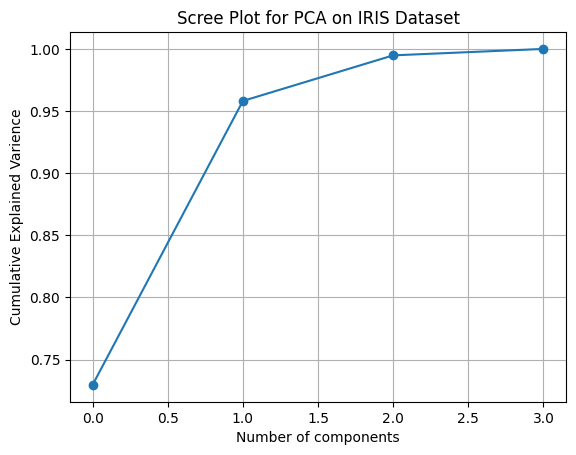

In [15]:
# Why? To visualize the 'elbow point' where adding  more components gives  little extra 
plt.plot(np.cumsum(pca.explained_variance_ratio_),marker = 'o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative Explained Varience')
plt.title('Scree Plot for PCA on IRIS Dataset')
plt.grid(True)
plt.show()

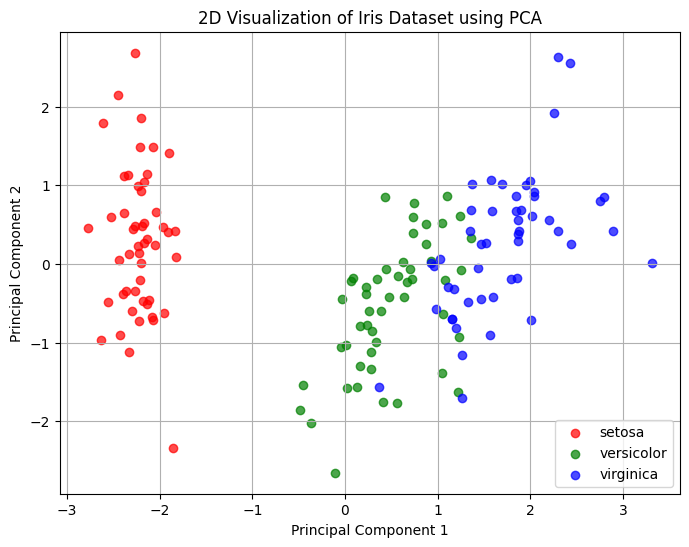

In [16]:
# step 4:
plt.figure(figsize=(8,6))
colours = ['red','green','blue']
for i , target in enumerate(np.unique(y)):
    plt.scatter(x_pca[y==target,0],x_pca[y==target,1],
                color=colours[i],label= target_names[i],alpha=0.7)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2D Visualization of Iris Dataset using PCA')
plt.legend()
plt.grid(True)
plt.show()